In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [84]:
def simulate_game(
    wealth: float=10000,
    f: float=0.2,
    n: int=200,
    paths: int=1000
) -> np.ndarray:

    """
    the game: A coin shows heads with probability p = 0.6. Each round you bet
              the fraction f ∈ [0, 1] of your wealth: it is multiplied by 1 + f 
              on heads and by 1 - f on tails

    args:
        wealth: the initial sum that is to be betted
        f: the fraction of the sum used in the model
        n: number of rounds
        paths: the number of simulated paths for each game

    """

    print(f"Params: wealth = {wealth}, f = {f}, n = {n}, \n paths = {paths}")
    w_list = np.zeros(shape=(paths, n))

    for path in range(paths):

        original_w = wealth
        for n_dim in range(n):
            
            multiplier = 1
            if np.random.random() < 0.4:
                multiplier = 1.0 - f
            else:
                multiplier = 1.0 + f
            wealth *= multiplier

            if wealth < 1e-13:
                break
            
            w_list[path, n_dim] = wealth
        
        wealth = original_w
    
    w_200 = [w_list[p, n - 1] for p in range(paths)]
    print(f"Mean W200 = {np.mean(w_200)}")
    print(f"Median W200 = {np.median(w_200)}")

    print("=" * 43)
    return w_list


In [71]:
def plot_path(simulated_path: np.ndarray) -> None:

    """ plot the simulated wealth trajectories """
    
    plt.figure(figsize=(12, 6))
    plt.xlabel("Round")
    plt.ylabel("Wealth (in LEI)")

    plt.grid(alpha=0.2)
    plt.plot(simulated_path)
    plt.show()

Params: wealth = 10000, f = 0.1, n = 200, 
 paths = 1000
Mean W200 = 500059.3336665452
Median W200 = 202545.67504427984


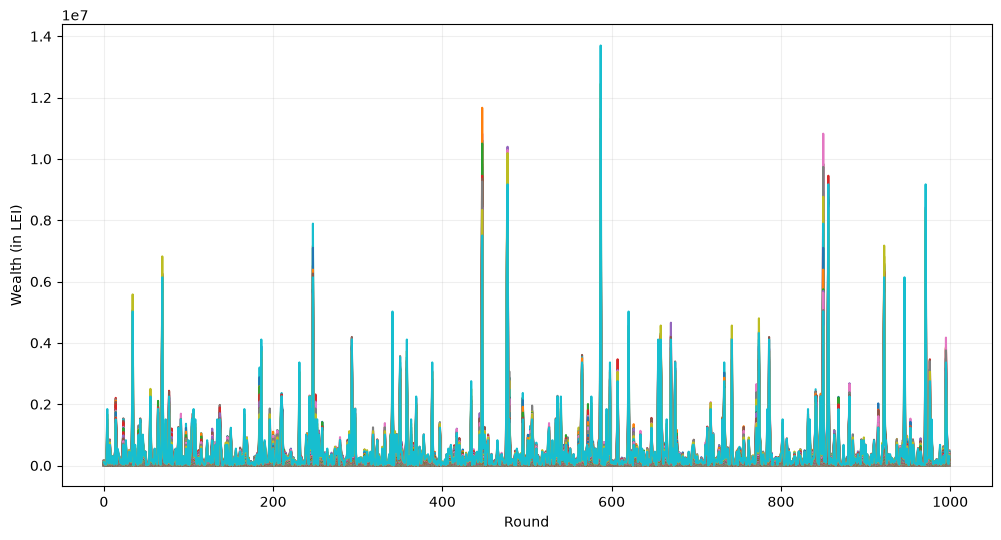

Params: wealth = 10000, f = 0.2, n = 200, 
 paths = 1000
Mean W200 = 18106291.967182036
Median W200 = 560981.4298660785


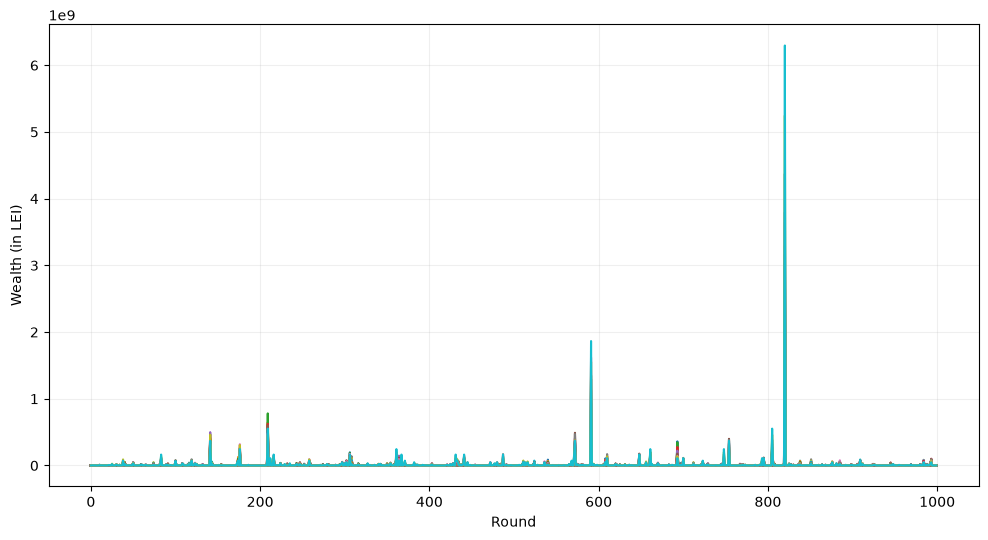

Params: wealth = 10000, f = 0.5, n = 200, 
 paths = 1000
Mean W200 = 3588076982.02583
Median W200 = 11.182822550841342


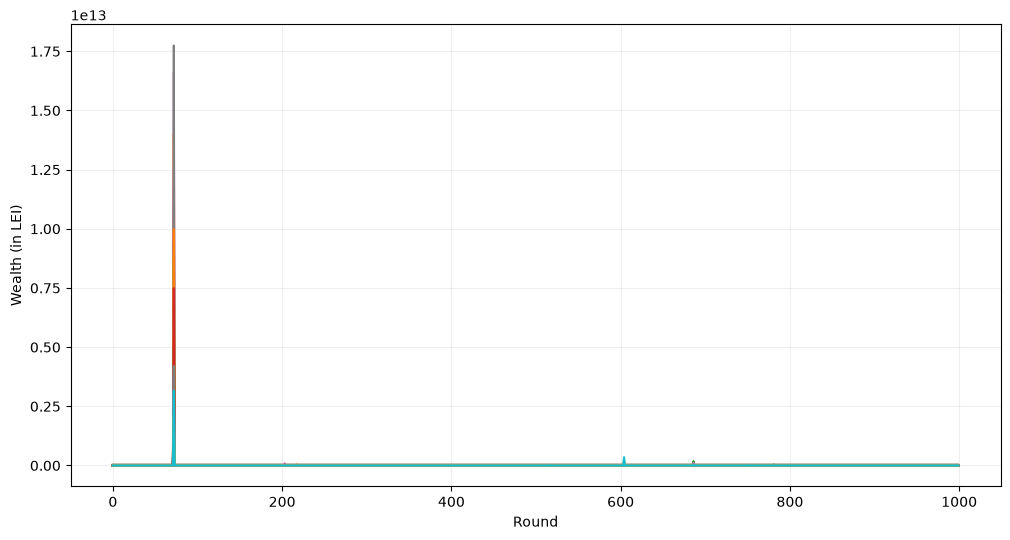

Params: wealth = 10000, f = 1, n = 200, 
 paths = 1000
Mean W200 = 0.0
Median W200 = 0.0


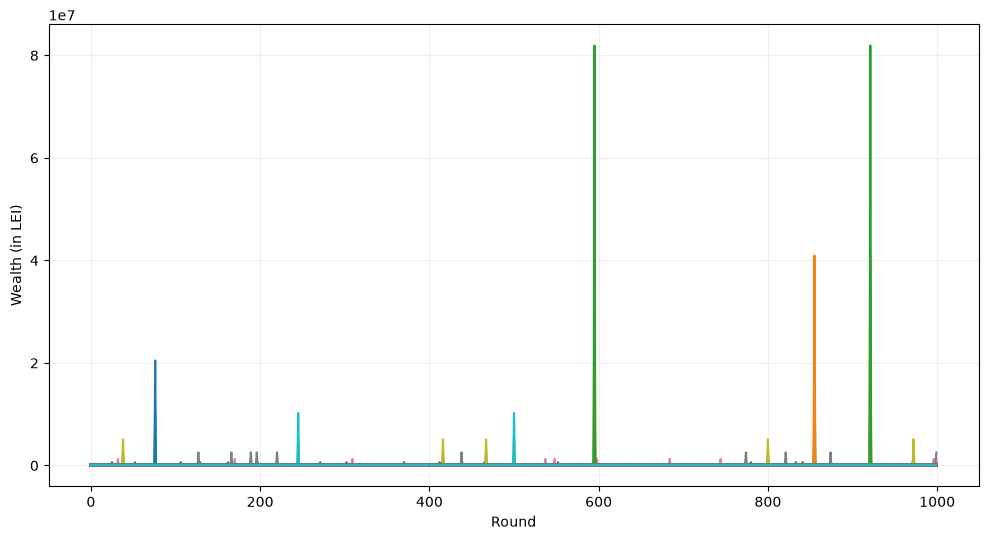

In [85]:
f_list = [0.1, 0.2, 0.5, 1]

w_list = [[] for _ in range(4)] 
for i in range(4):
    w_list[i] = simulate_game(f=f_list[i])
    plot_path(w_list[i])